数据维度: (6606, 24)
训练集: (4624, 24), 测试集: (1982, 24)

PART 1: DoubleML ATE 估计（4个关键变量）

>>> 正在估计 Hours_Studied 的 ATE...
    ATE = 0.2938 (95% CI: [0.2838, 0.3038])

>>> 正在估计 Attendance 的 ATE...
    ATE = 0.1989 (95% CI: [0.1945, 0.2033])

>>> 正在估计 Access_to_Resources 的 ATE...
    ATE = 1.0103 (95% CI: [0.9303, 1.0904])

>>> 正在估计 Parental_Involvement 的 ATE...
    ATE = 1.0171 (95% CI: [0.9318, 1.1025])

=== ATE 汇总表 ===
              Treatment     ATE  CI_Lower  CI_Upper
1            Attendance  0.1989    0.1945    0.2033
0         Hours_Studied  0.2938    0.2838    0.3038
2   Access_to_Resources  1.0103    0.9303    1.0904
3  Parental_Involvement  1.0171    0.9318    1.1025


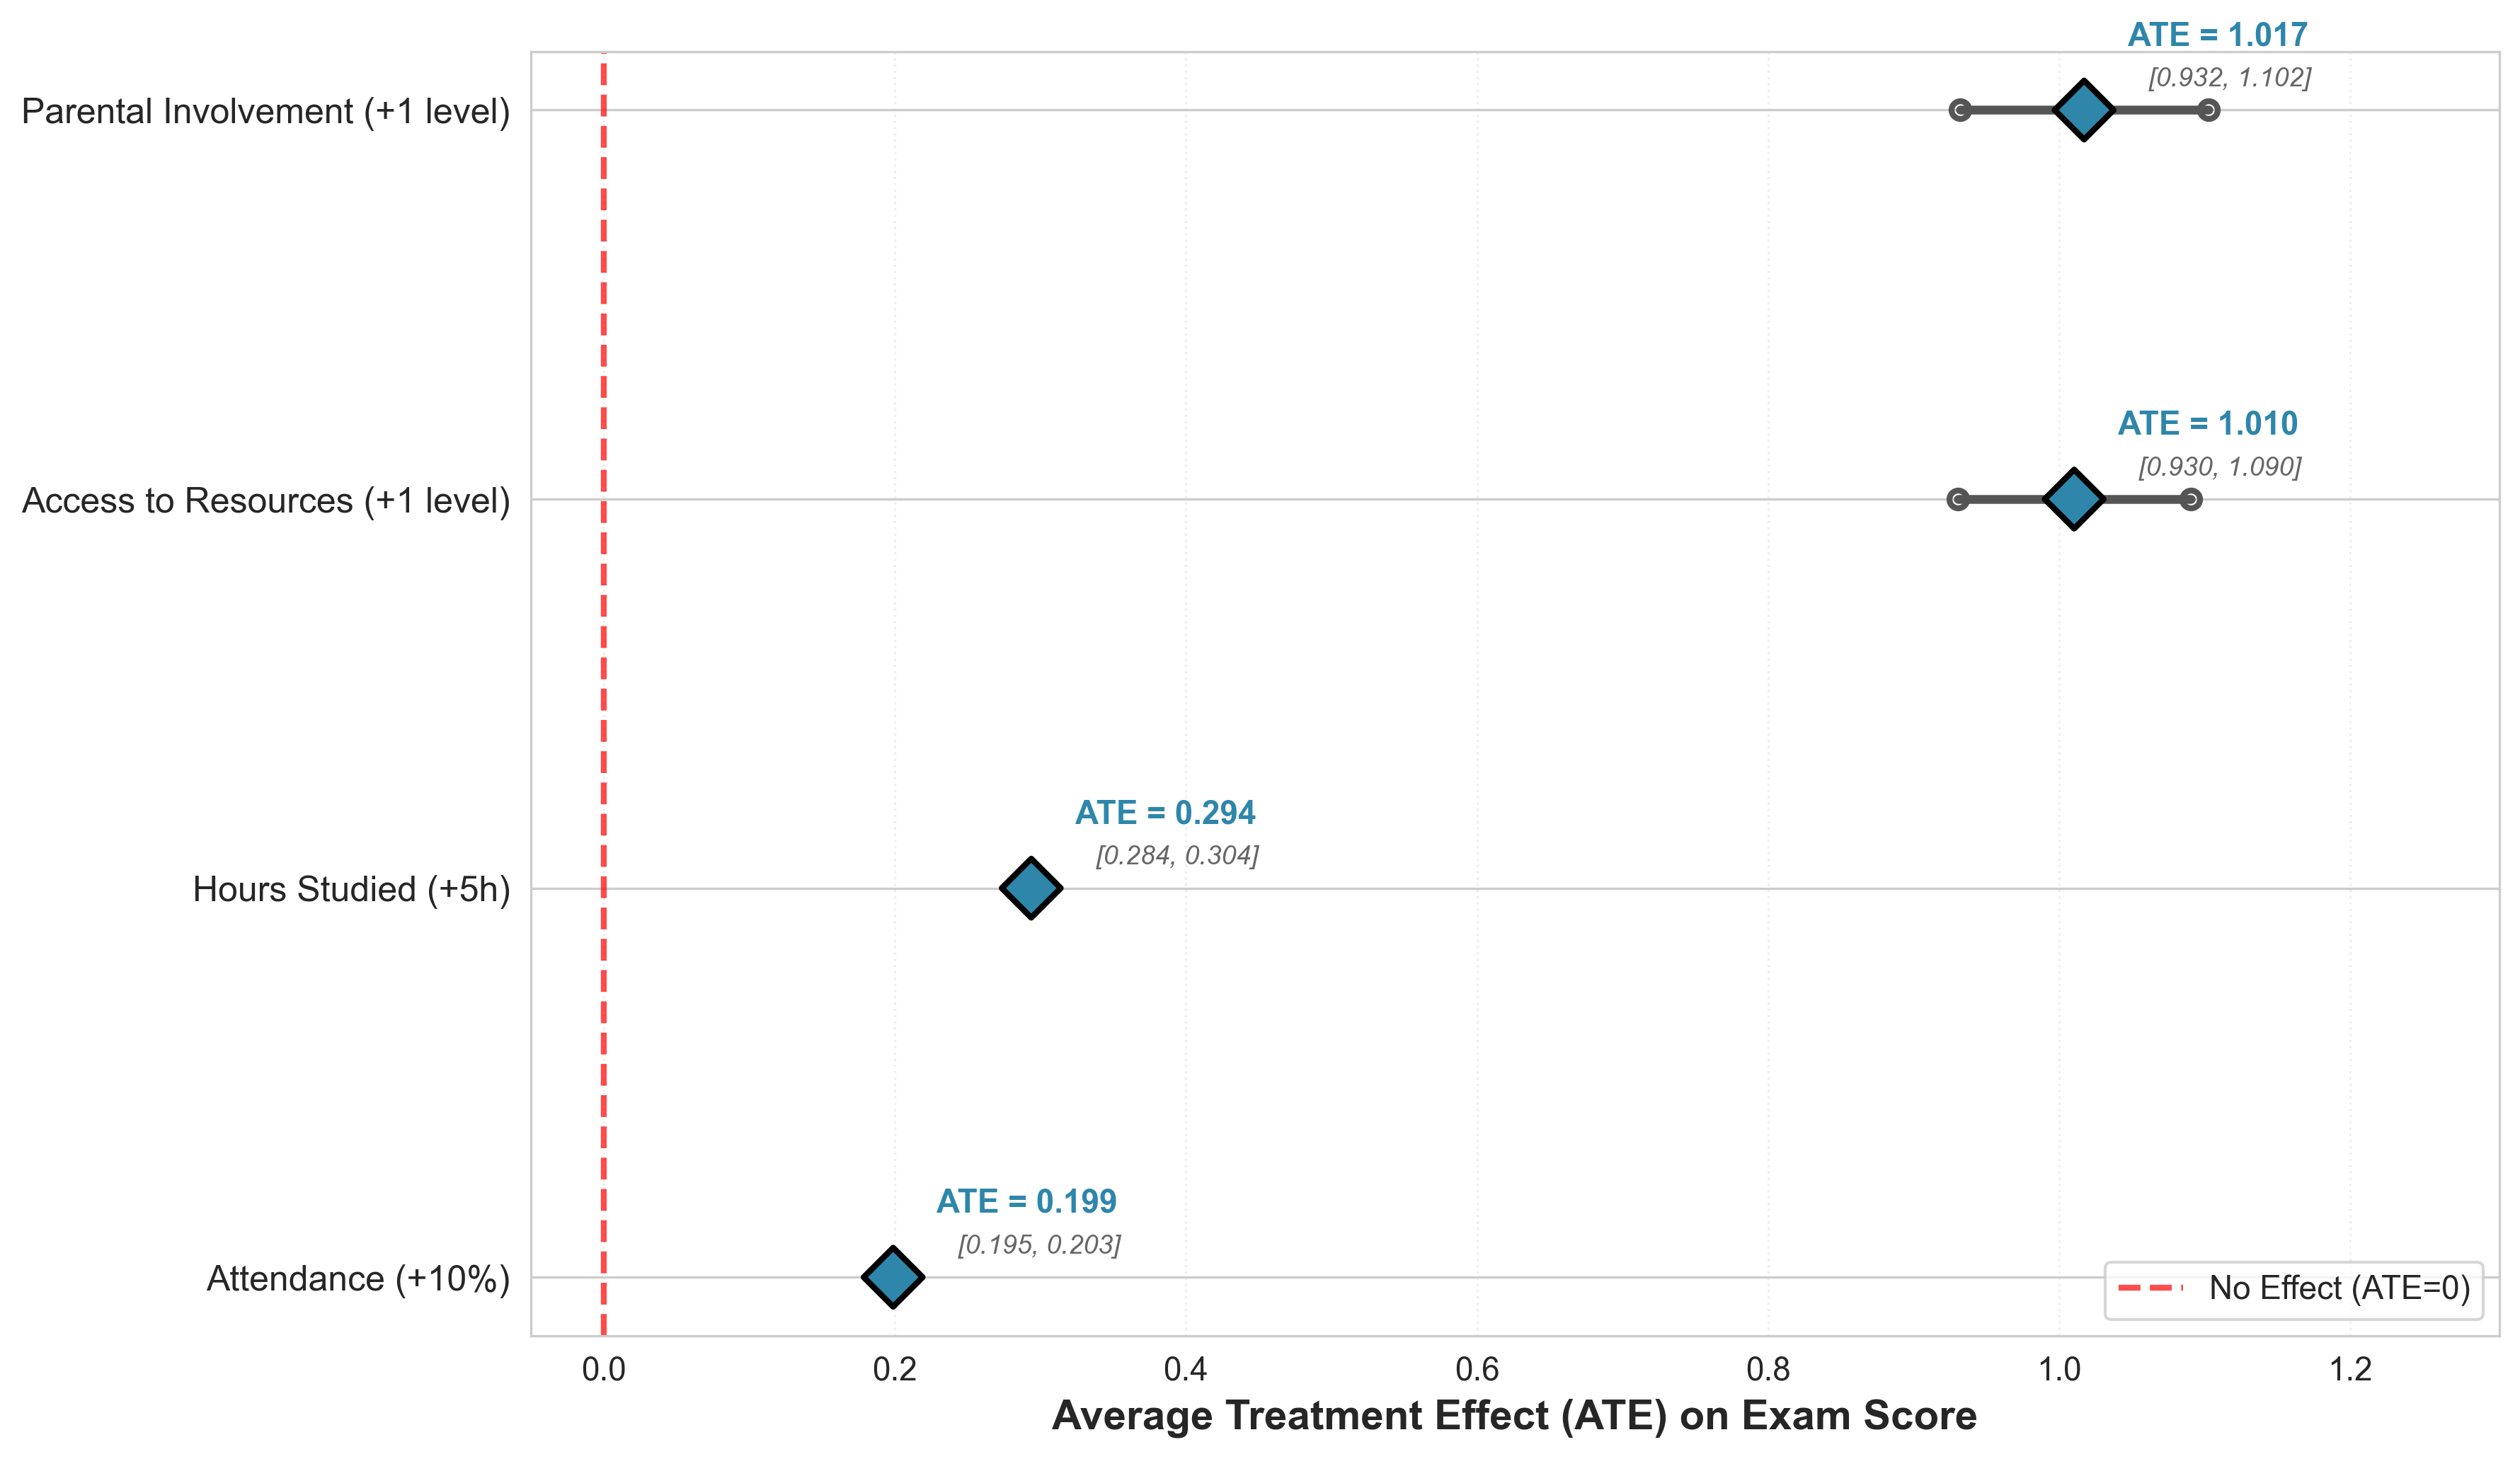


✅ ATE 森林图已保存: fig_ate_forest_plot_4vars.png

PART 2: CATE 异质性分析（4个关键变量，反事实预测）

训练 Gradient Boosting 基础模型...
基础模型测试集 R²: 0.6739

>>> 正在计算 Hours_Studied (+5 hours) 的 CATE...


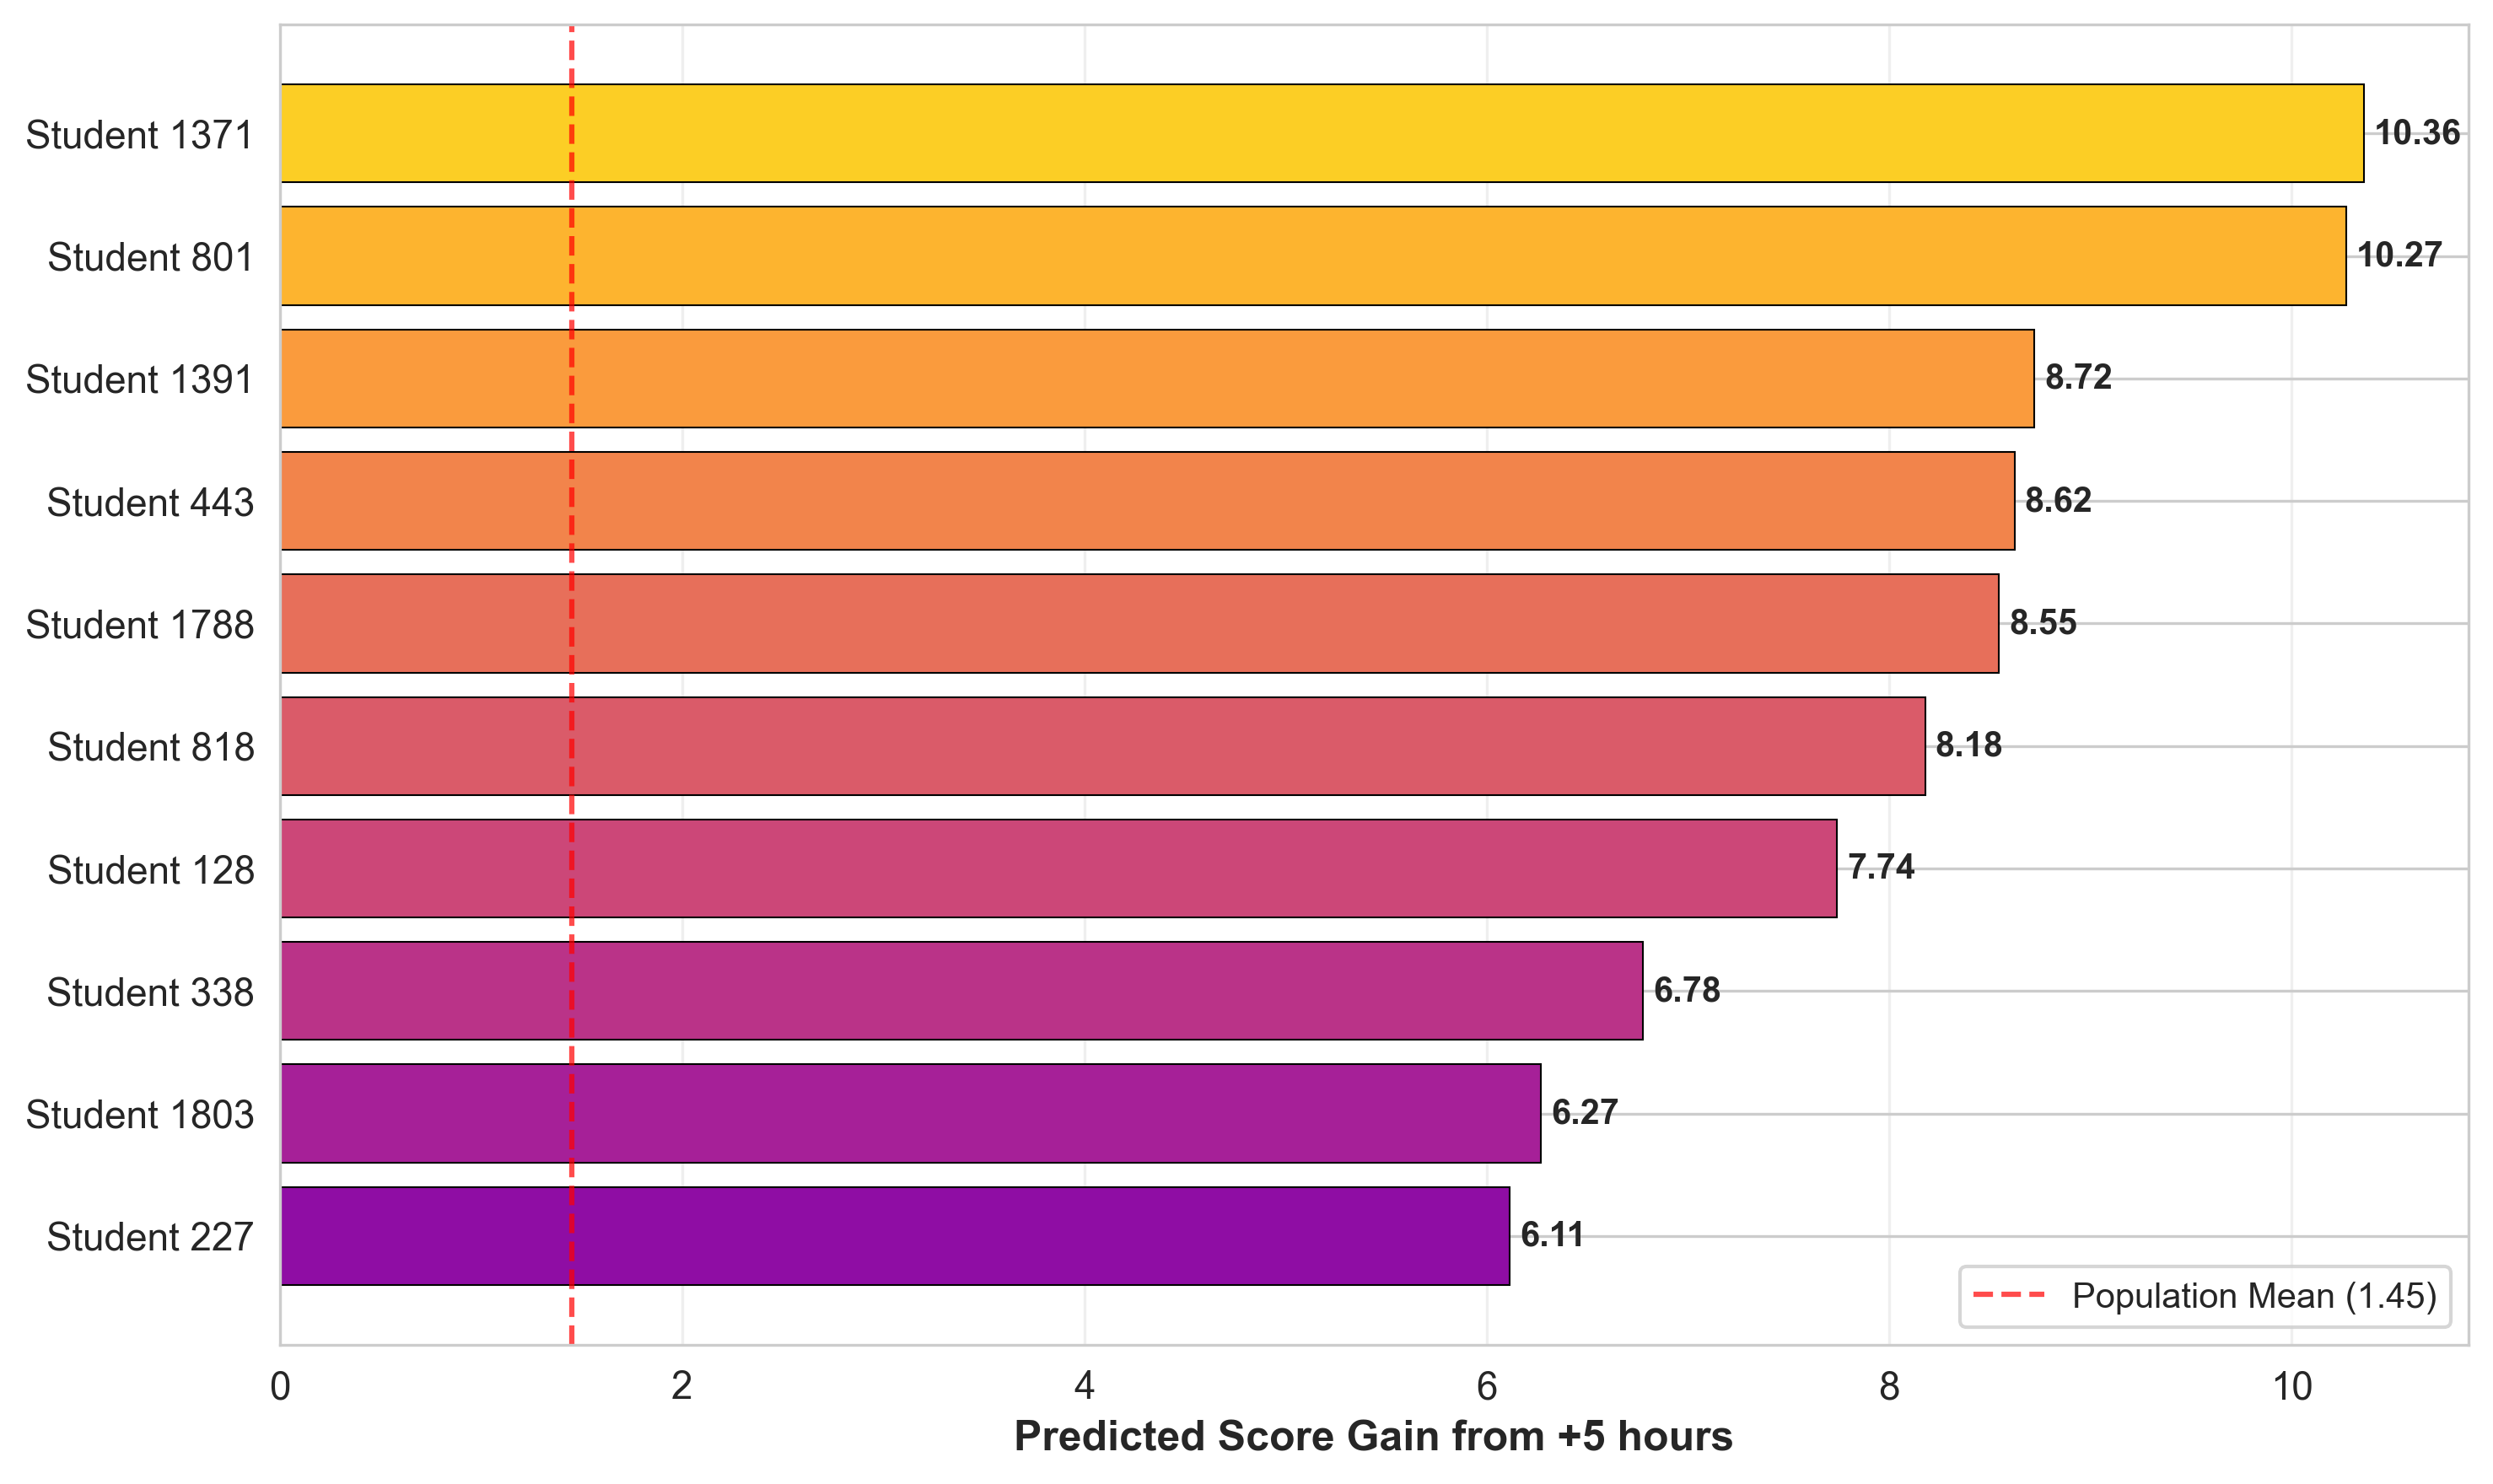

    ✅ CATE Top10 图已保存: fig_cate_top10_hours_studied.png

    Top 10 受益学生 (Hours_Studied):
 Rank  Student_Index  Base_Score  Counterfactual_Score  Benefit
    1           1371       65.84                 76.20    10.36
    2            801       67.68                 77.95    10.27
    3           1391       71.35                 80.07     8.72
    4            443       67.41                 76.03     8.62
    5           1788       70.56                 79.11     8.55
    6            818       65.90                 74.08     8.18
    7            128       71.53                 79.27     7.74
    8            338       68.31                 75.08     6.78
    9           1803       64.92                 71.19     6.27
   10            227       68.06                 74.17     6.11

>>> 正在计算 Attendance (+10% attendance) 的 CATE...


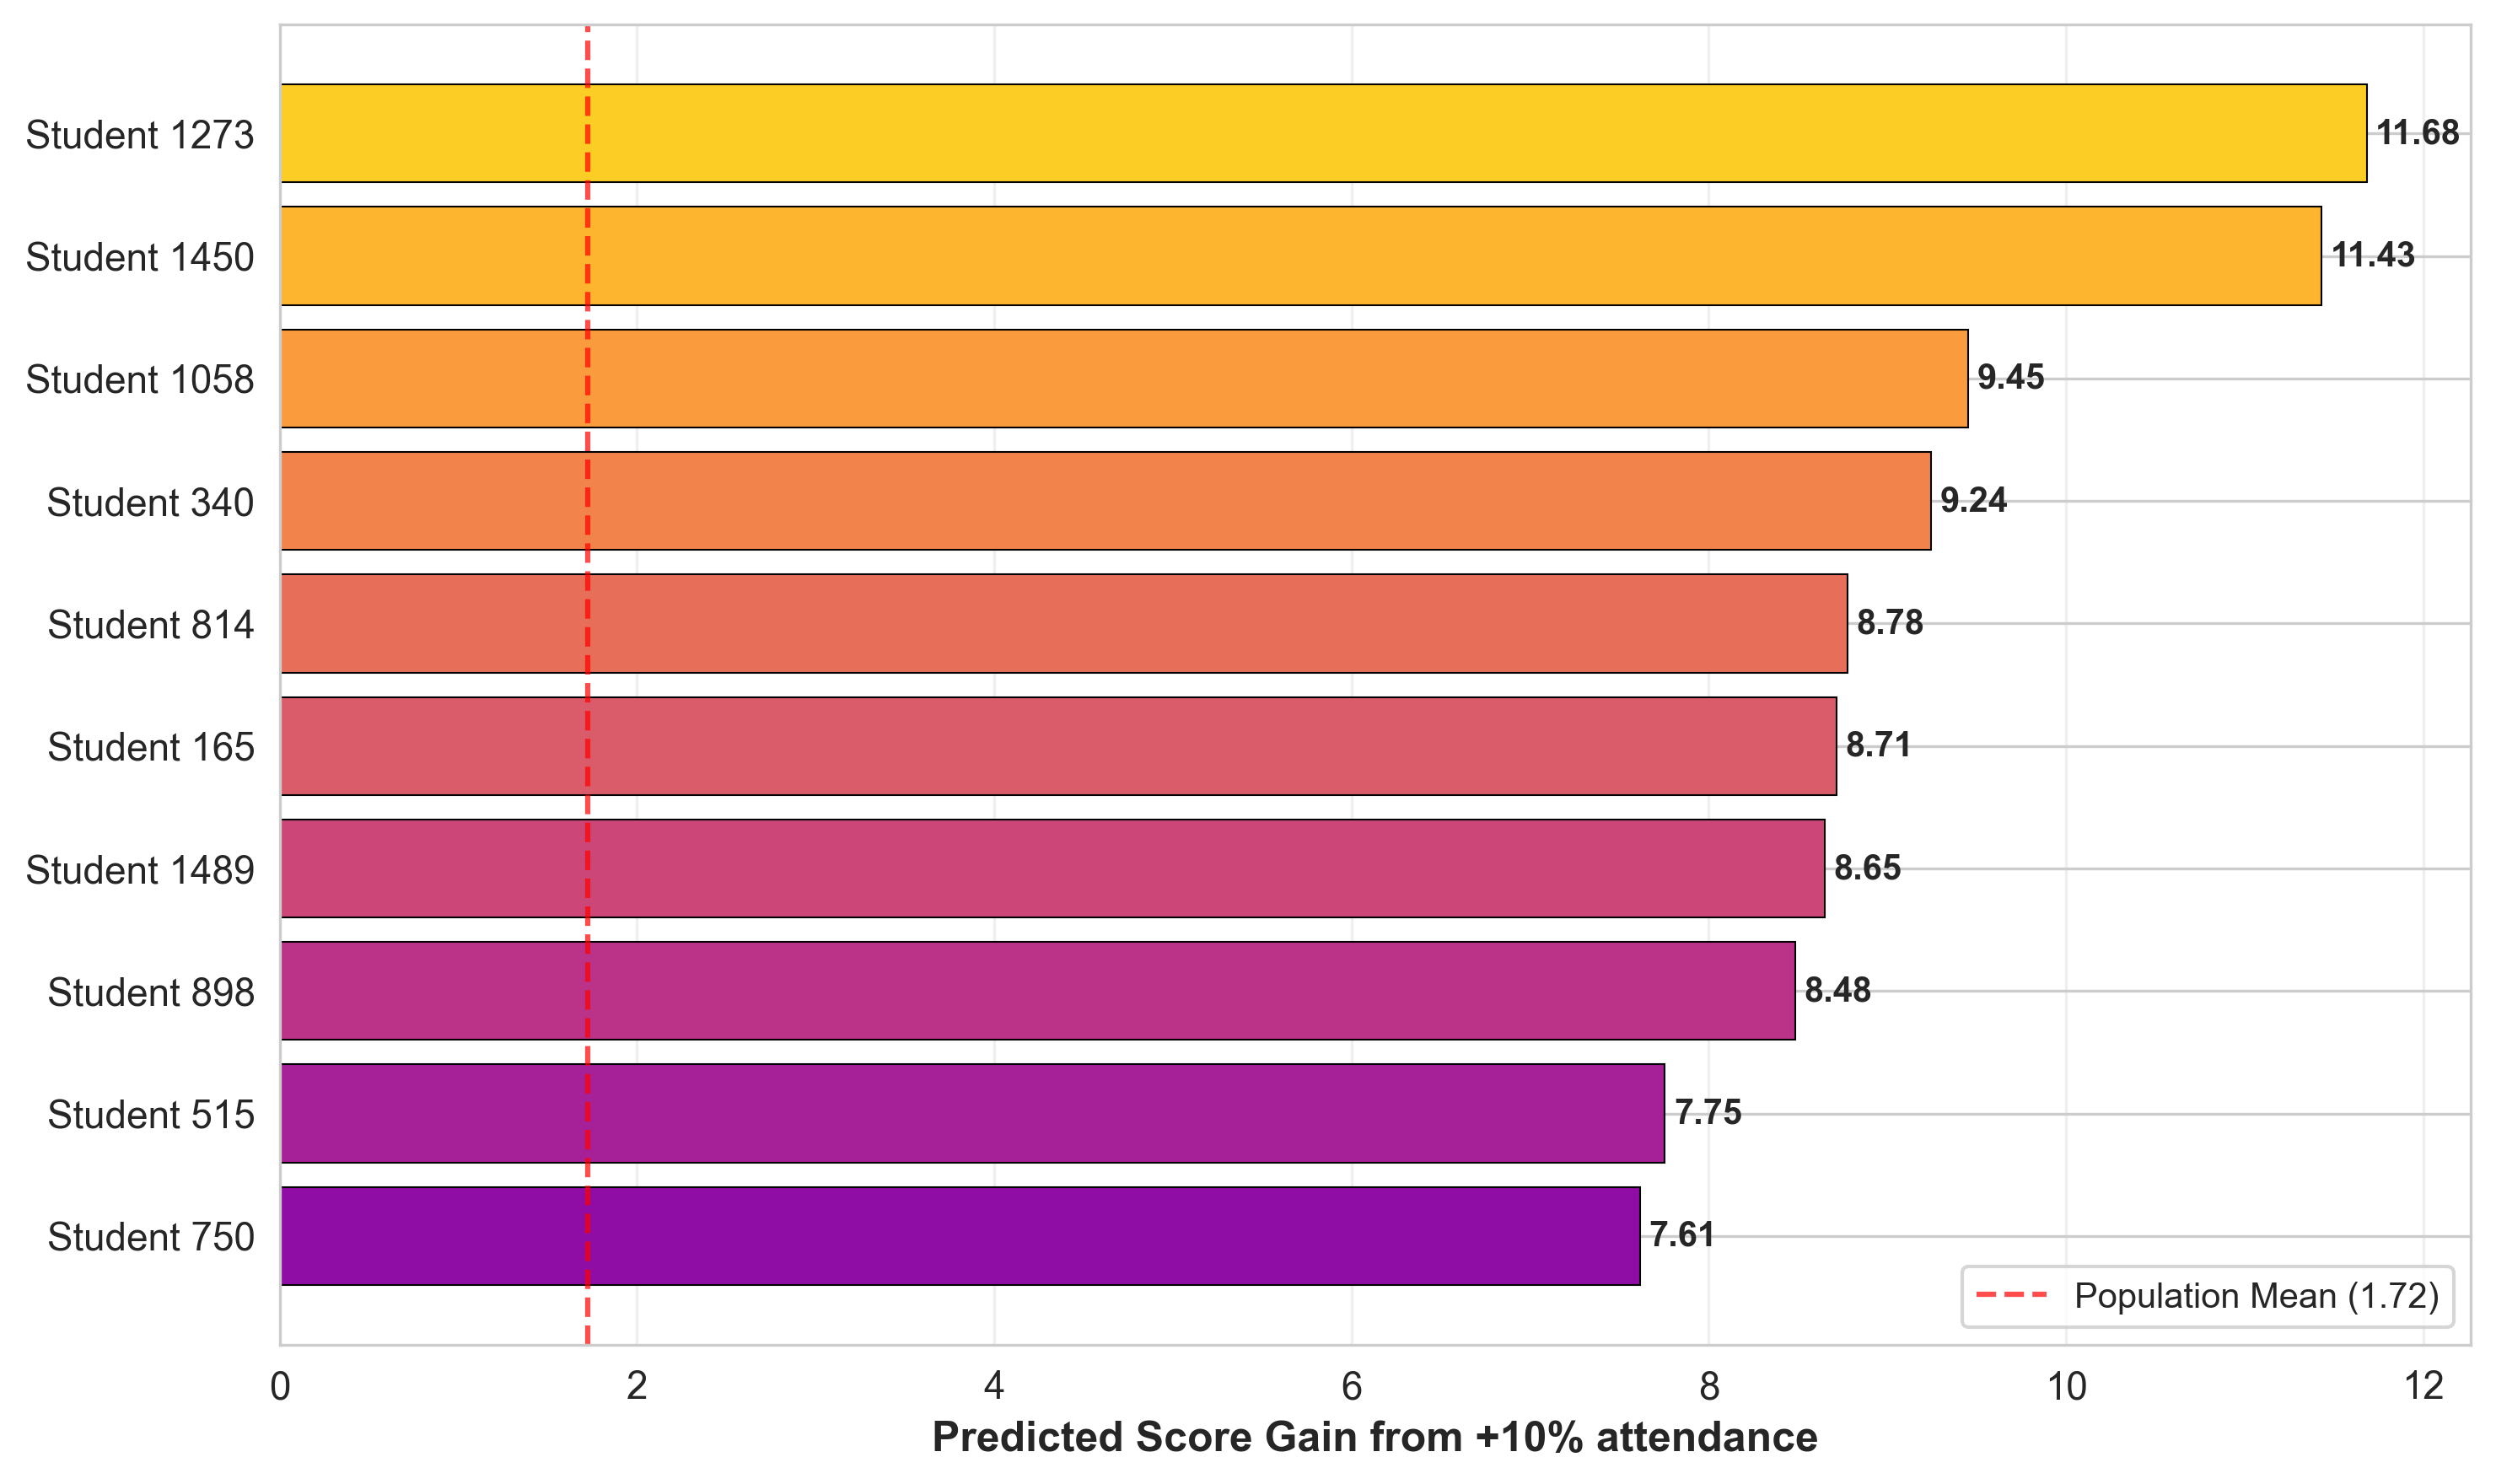

    ✅ CATE Top10 图已保存: fig_cate_top10_attendance.png

    Top 10 受益学生 (Attendance):
 Rank  Student_Index  Base_Score  Counterfactual_Score  Benefit
    1           1273       72.54                 84.23    11.68
    2           1450       73.36                 84.79    11.43
    3           1058       73.73                 83.18     9.45
    4            340       71.08                 80.32     9.24
    5            814       69.02                 77.80     8.78
    6            165       73.18                 81.89     8.71
    7           1489       72.60                 81.25     8.65
    8            898       72.99                 81.47     8.48
    9            515       66.74                 74.49     7.75
   10            750       66.20                 73.81     7.61

>>> 正在计算 Access_to_Resources (+1 level) 的 CATE...


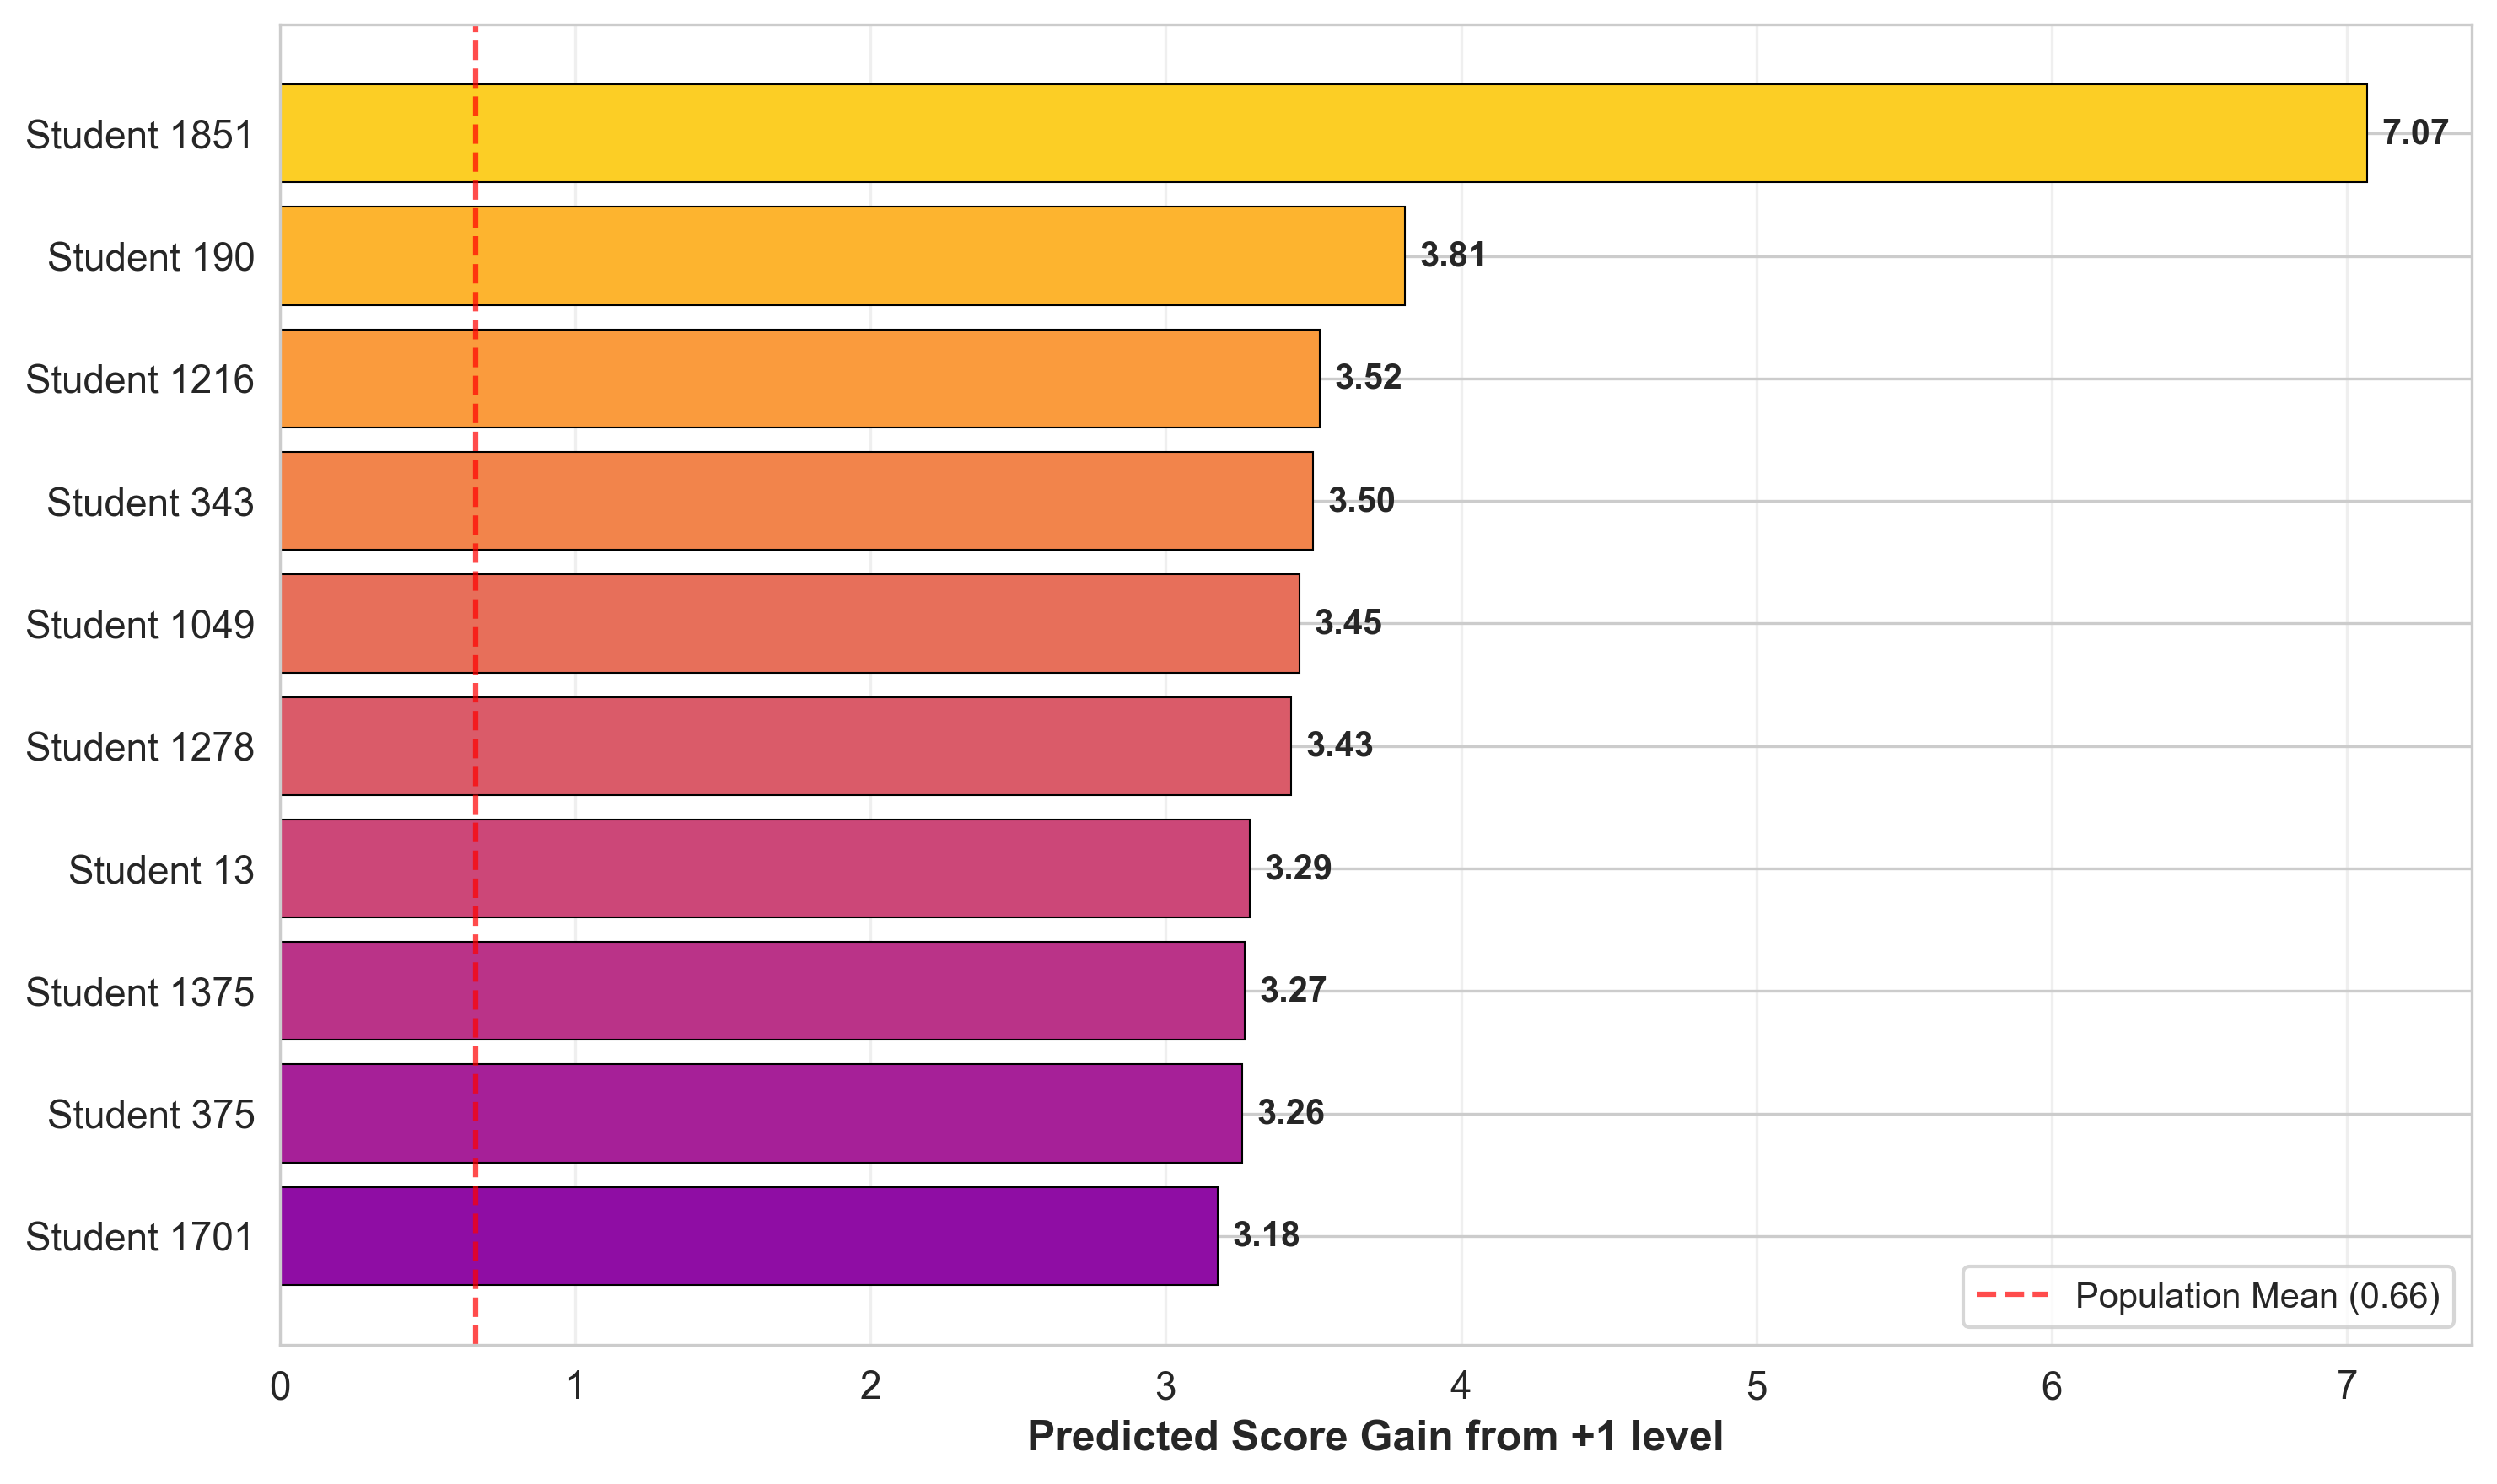

    ✅ CATE Top10 图已保存: fig_cate_top10_access_to_resources.png

    Top 10 受益学生 (Access_to_Resources):
 Rank  Student_Index  Base_Score  Counterfactual_Score  Benefit
    1           1851       69.05                 76.12     7.07
    2            190       69.08                 72.89     3.81
    3           1216       64.51                 68.03     3.52
    4            343       66.63                 70.13     3.50
    5           1049       65.94                 69.39     3.45
    6           1278       69.99                 73.41     3.43
    7             13       69.51                 72.79     3.29
    8           1375       63.53                 66.80     3.27
    9            375       66.88                 70.14     3.26
   10           1701       64.85                 68.02     3.18

>>> 正在计算 Parental_Involvement (+1 level) 的 CATE...


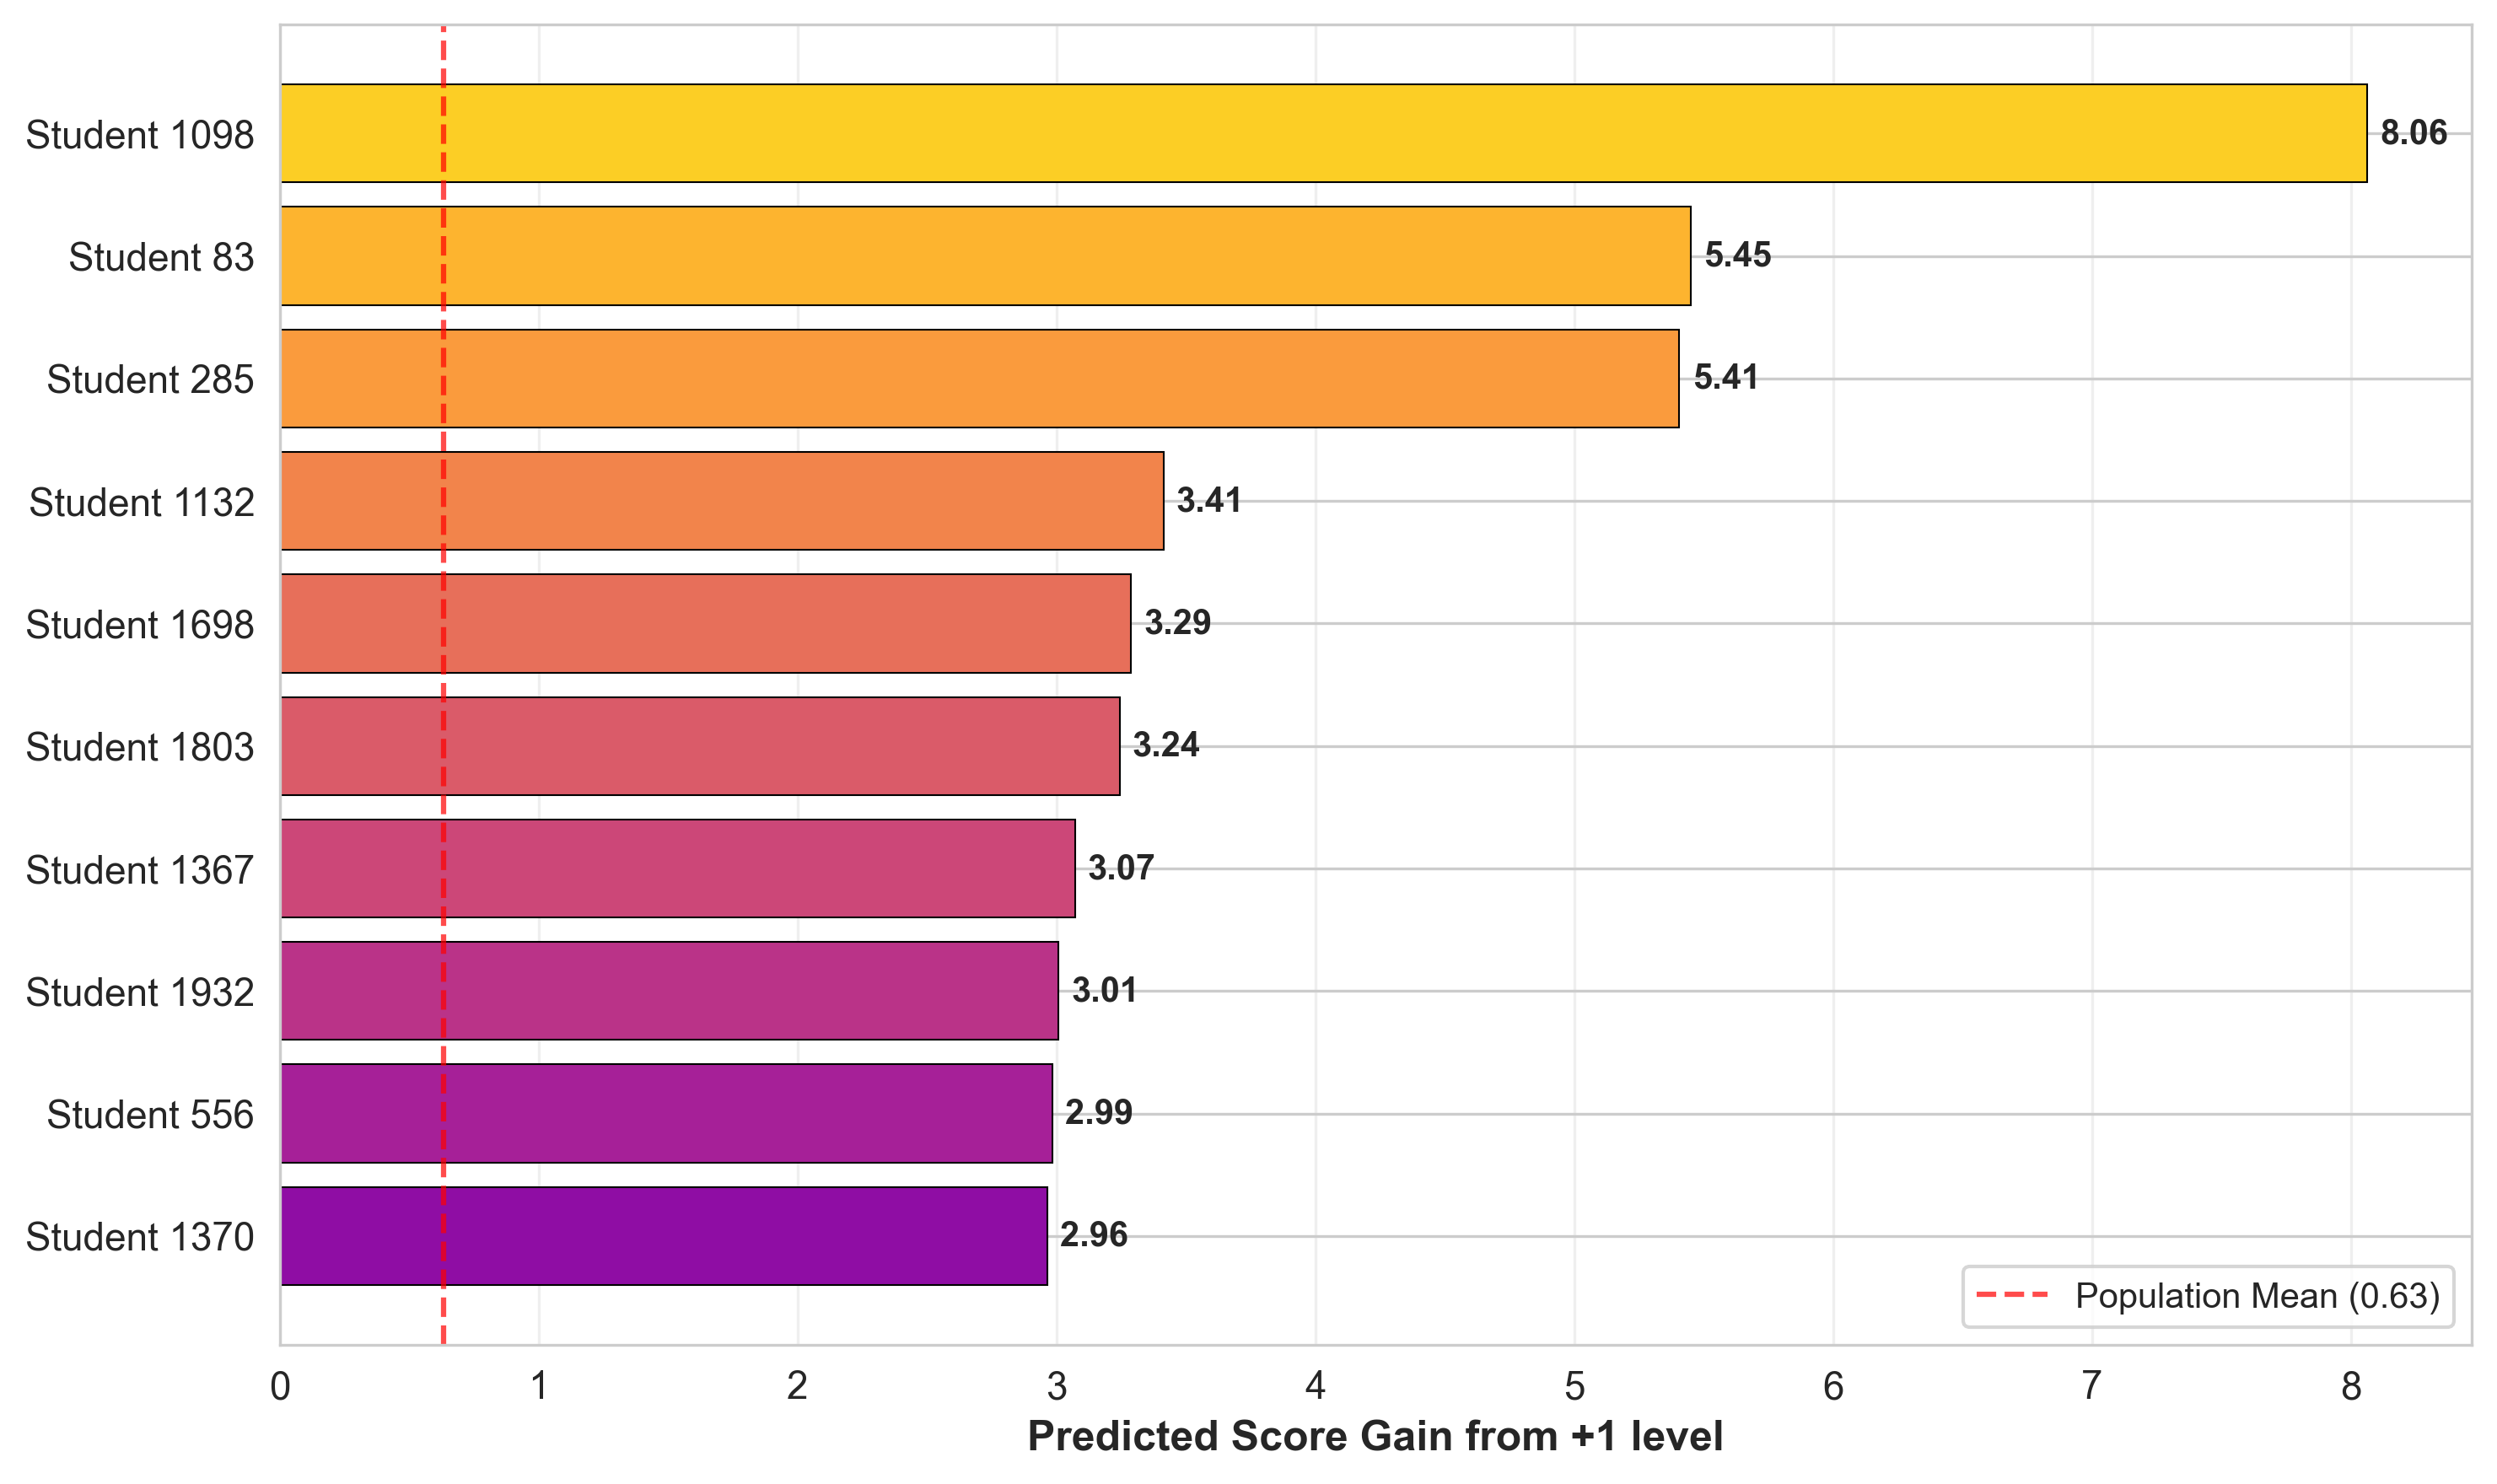

    ✅ CATE Top10 图已保存: fig_cate_top10_parental_involvement.png

    Top 10 受益学生 (Parental_Involvement):
 Rank  Student_Index  Base_Score  Counterfactual_Score  Benefit
    1           1098       70.55                 78.61     8.06
    2             83       68.43                 73.88     5.45
    3            285       67.32                 72.72     5.41
    4           1132       68.84                 72.25     3.41
    5           1698       67.39                 70.68     3.29
    6           1803       64.92                 68.17     3.24
    7           1367       67.46                 70.53     3.07
    8           1932       70.35                 73.36     3.01
    9            556       69.49                 72.47     2.99
   10           1370       65.48                 68.44     2.96

=== CATE 异质性汇总表 ===
              Treatment  Mean_Benefit  Std_Benefit  Max_Benefit  Top10_Mean  \
0         Hours_Studied        1.4527       0.9059      10.3614      8.1606   
1            

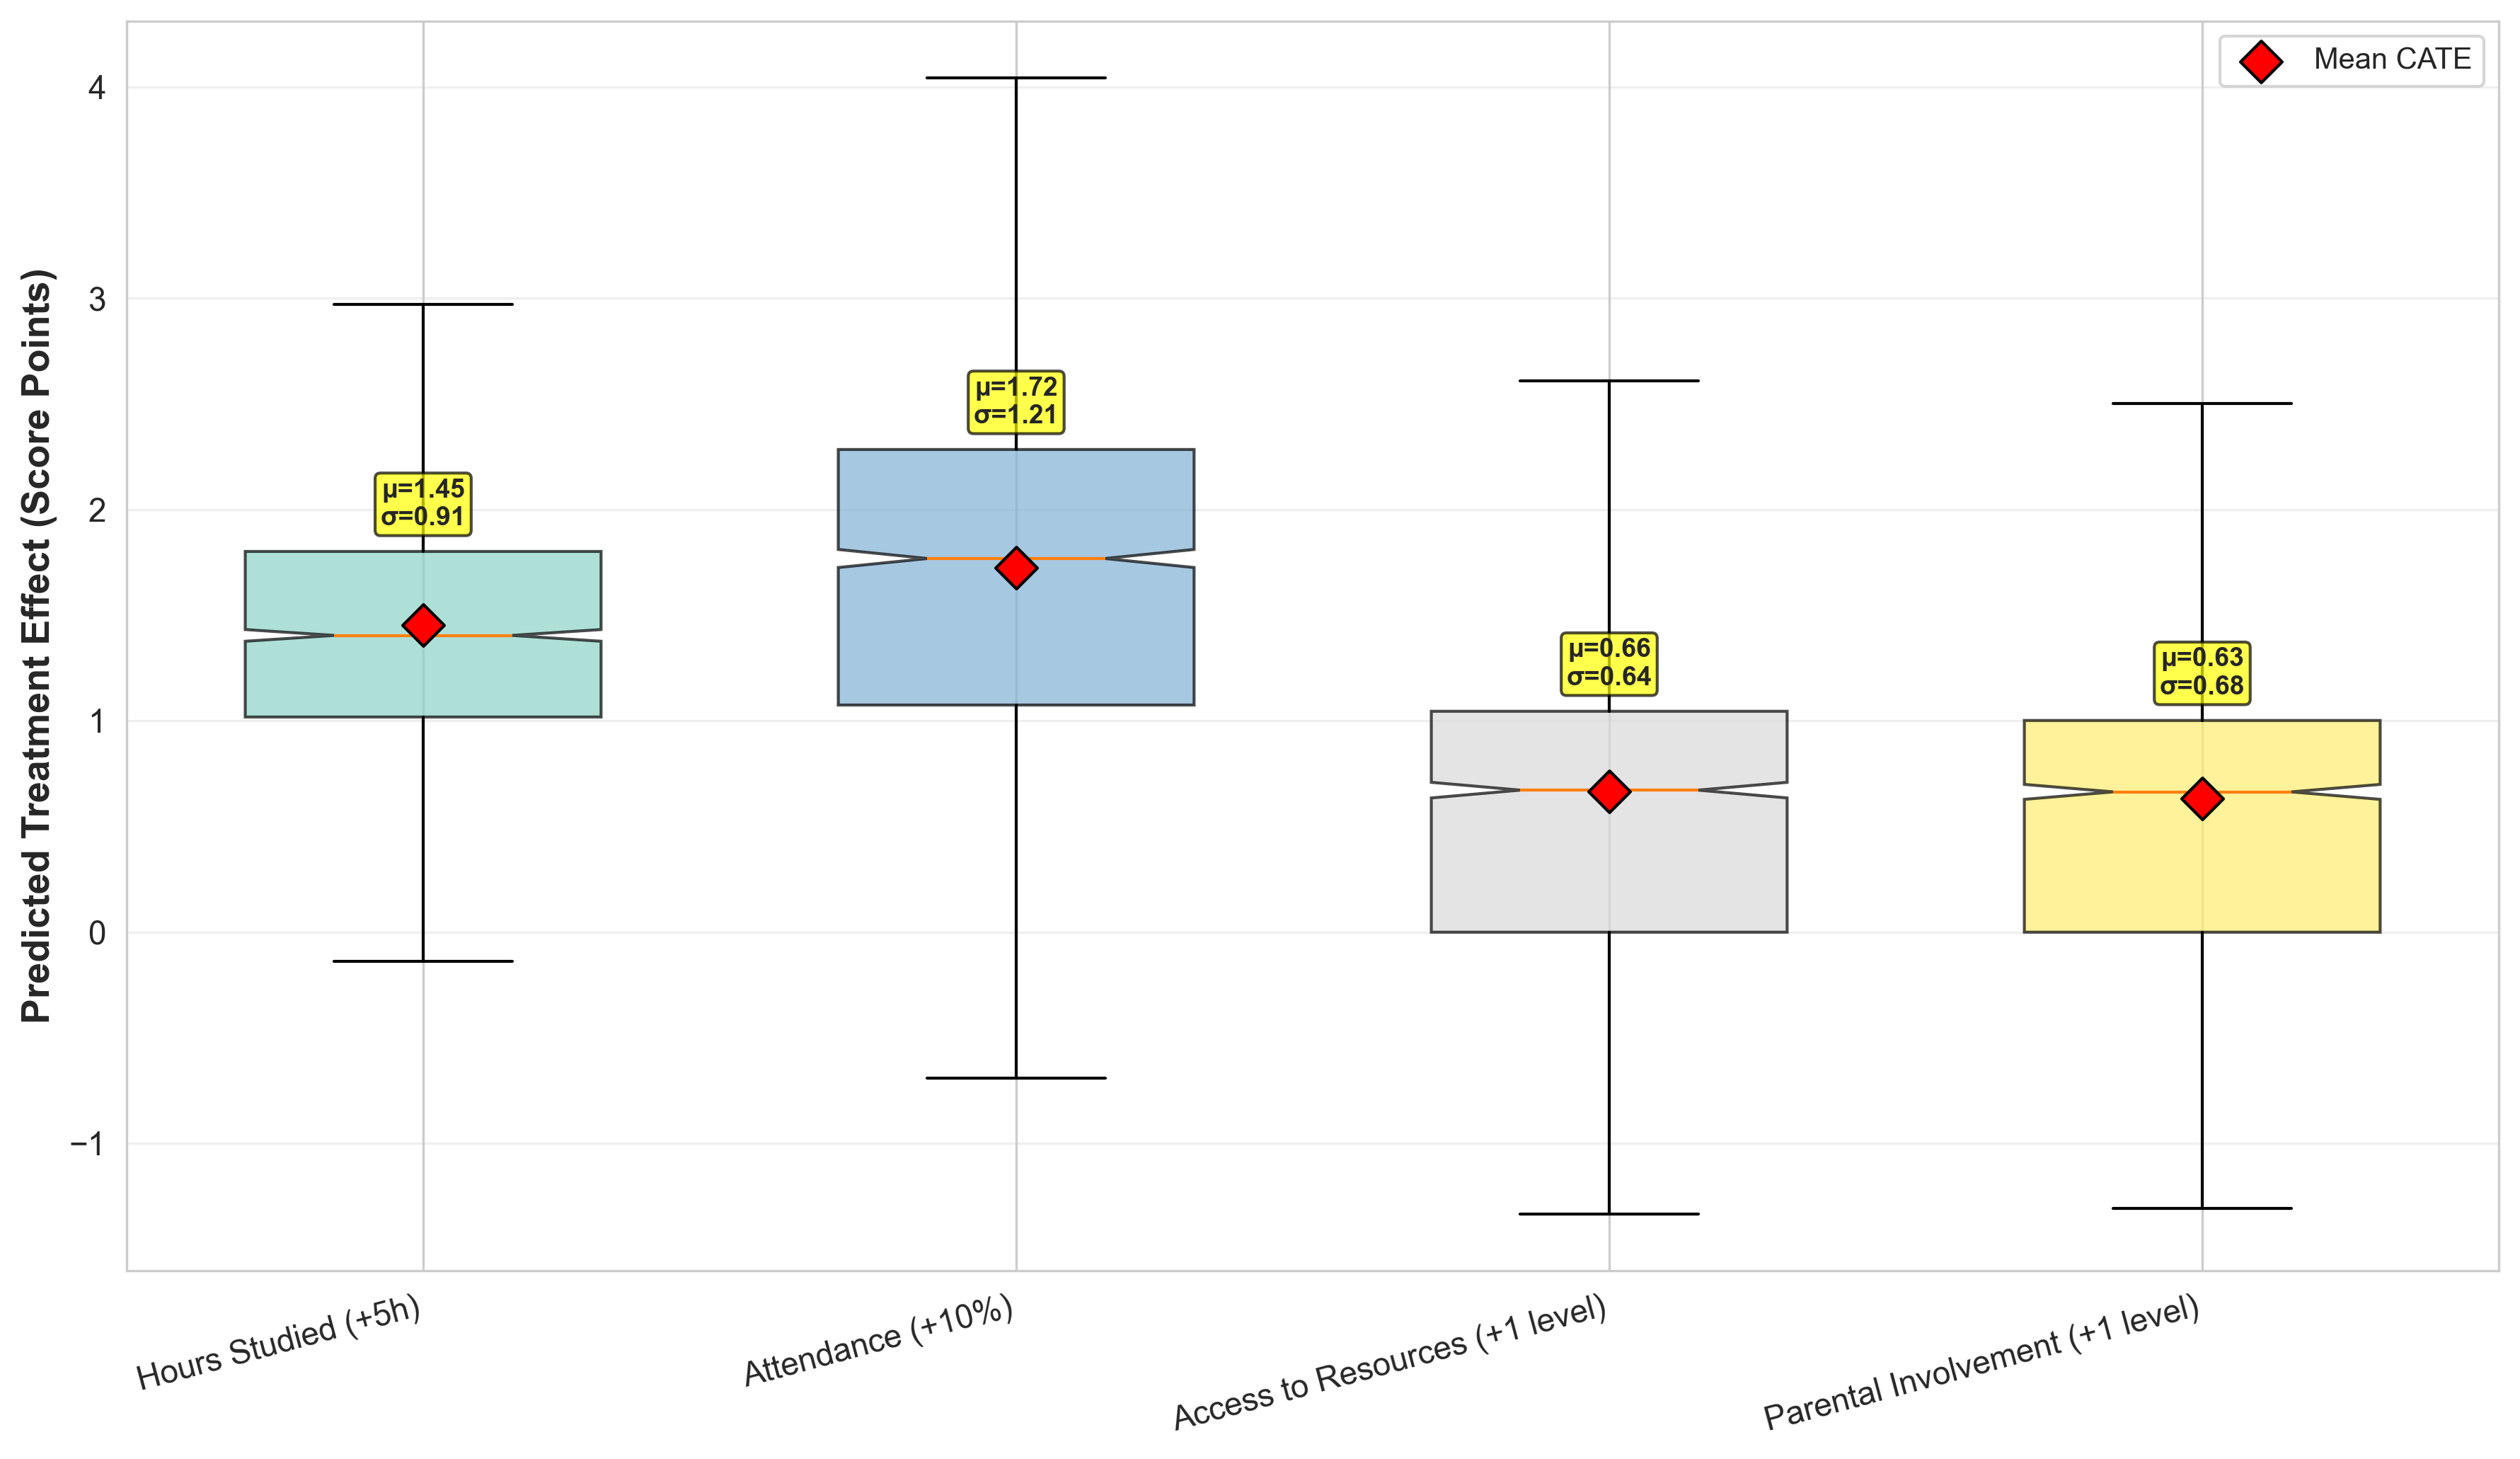


✅ CATE 分布汇总图已保存: fig_cate_distribution_4vars.png

联合结果（ATE + CATE 异质性）:
              Treatment     ATE  CI_Lower  CI_Upper  Mean_Benefit  \
0            Attendance  0.1989    0.1945    0.2033        1.7234   
1         Hours_Studied  0.2938    0.2838    0.3038        1.4527   
2   Access_to_Resources  1.0103    0.9303    1.0904        0.6646   
3  Parental_Involvement  1.0171    0.9318    1.1025        0.6337   

   Std_Benefit  Max_Benefit  Top10_Mean  
0       1.2088      11.6830      9.1801  
1       0.9059      10.3614      8.1606  
2       0.6427       7.0685      3.7762  
3       0.6785       8.0630      4.0894  


In [28]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from doubleml import DoubleMLData, DoubleMLPLR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')


plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['legend.fontsize'] = 10
sns.set_style("whitegrid")


df = pd.read_csv('StudentPerformanceFactors.csv')
df_clean = df[df['Exam_Score'] <= 100].copy()


for col in df_clean.columns:
    if df_clean[col].dtype == 'object':
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
    else:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())


ordinal_mappings = {
    'Motivation_Level': {'Low': 0, 'Medium': 1, 'High': 2},
    'Parental_Involvement': {'Low': 0, 'Medium': 1, 'High': 2},
    'Teacher_Quality': {'Low': 0, 'Medium': 1, 'High': 2},
    'Family_Income': {'Low': 0, 'Medium': 1, 'High': 2},
    'Distance_from_Home': {'Near': 0, 'Moderate': 1, 'Far': 2},
    'Access_to_Resources': {'Low': 0, 'Medium': 1, 'High': 2},
    'Peer_Influence': {'Negative': 0, 'Neutral': 1, 'Positive': 2},
    'Parental_Education_Level': {'High School': 0, 'College': 1, 'Postgraduate': 2},
}

for col, mapping in ordinal_mappings.items():
    df_clean[col] = df_clean[col].map(mapping)


numeric_cols = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 
                'Tutoring_Sessions', 'Physical_Activity']
cat_cols = ['School_Type', 'Gender', 'Internet_Access', 
            'Extracurricular_Activities', 'Learning_Disabilities']

feature_cols = numeric_cols + list(ordinal_mappings.keys()) + cat_cols
X = df_clean[feature_cols].copy()
y = df_clean['Exam_Score'].copy()

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=False)


X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.3, random_state=42
)

print(f"数据维度: {X_encoded.shape}")
print(f"训练集: {X_train.shape}, 测试集: {X_test.shape}")


print("\n" + "="*60)
print("PART 1: DoubleML ATE 估计（4个关键变量）")
print("="*60)


key_treatments = {
    'Hours_Studied': {'delta': 5, 'desc': '+5 hours'},
    'Attendance': {'delta': 10, 'desc': '+10% attendance'},
    'Access_to_Resources': {'delta': 1, 'desc': '+1 level'},
    'Parental_Involvement': {'delta': 1, 'desc': '+1 level'}
}


ml_g = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
ml_m = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)

ate_results = []

for treatment, info in key_treatments.items():
    if treatment not in X_encoded.columns:
        print(f"跳过 {treatment}（不在编码后特征中）")
        continue

    print(f"\n>>> 正在估计 {treatment} 的 ATE...")


    dml_data = DoubleMLData(
        data=pd.concat([X_encoded.reset_index(drop=True), y.reset_index(drop=True)], axis=1),
        y_col='Exam_Score',
        d_cols=treatment,
        x_cols=[col for col in X_encoded.columns if col != treatment]
    )


    ml_g_temp = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)
    ml_m_temp = RandomForestRegressor(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1)

    dml_plr = DoubleMLPLR(dml_data, ml_g_temp, ml_m_temp, n_folds=5)
    dml_plr.fit()

    ate = dml_plr.coef[0]
    ci = dml_plr.confint()
    ci_lower = ci.iloc[0, 0]
    ci_upper = ci.iloc[0, 1]

    ate_results.append({
        'Treatment': treatment,
        'ATE': ate,
        'CI_Lower': ci_lower,
        'CI_Upper': ci_upper,
        'Delta': info['delta'],
        'Desc': info['desc']
    })

    print(f"    ATE = {ate:.4f} (95% CI: [{ci_lower:.4f}, {ci_upper:.4f}])")

ate_df = pd.DataFrame(ate_results)
ate_df = ate_df.sort_values('ATE', ascending=True)  
print("\n=== ATE 汇总表 ===")
print(ate_df[['Treatment', 'ATE', 'CI_Lower', 'CI_Upper']].round(4))


ate_df.to_csv('ate_results_4variables.csv', index=False)


fig, ax = plt.subplots(figsize=(12, 7))

y_pos = np.arange(len(ate_df))
colors = ['#2E86AB' if row['ATE'] > 0 else '#A23B72' for _, row in ate_df.iterrows()]


for i, (_, row) in enumerate(ate_df.iterrows()):
    ci_width = row['CI_Upper'] - row['CI_Lower']

    ax.plot([row['CI_Lower'], row['CI_Upper']], [i, i], 
            color='#555555', linewidth=3, zorder=1, solid_capstyle='round')

    ax.plot(row['CI_Lower'], i, marker='o', markersize=6, 
            color='#555555', zorder=2, fillstyle='none', markeredgewidth=2)
    ax.plot(row['CI_Upper'], i, marker='o', markersize=6, 
            color='#555555', zorder=2, fillstyle='none', markeredgewidth=2)
    if ci_width < 0.05:
        ax.plot([row['CI_Lower'], row['CI_Upper']], [i, i], 
                color='#333333', linewidth=5, zorder=1, alpha=0.8)


ax.scatter(ate_df['ATE'], y_pos, color=colors, s=200, zorder=5, 
           edgecolors='black', linewidth=2, marker='D')


ax.axvline(x=0, color='red', linestyle='--', linewidth=2, alpha=0.7, label='No Effect (ATE=0)')


treatment_labels = {
    'Hours_Studied': 'Hours Studied (+5h)',
    'Attendance': 'Attendance (+10%)',
    'Access_to_Resources': 'Access to Resources (+1 level)',
    'Parental_Involvement': 'Parental Involvement (+1 level)'
}
ax.set_yticks(y_pos)
ax.set_yticklabels([treatment_labels.get(t, t) for t in ate_df['Treatment']], fontsize=12)
ax.set_xlabel('Average Treatment Effect (ATE) on Exam Score', fontsize=14, fontweight='bold')
#ax.set_title('DoubleML ATE Estimates for Manipulable Educational Factors\n(95% Confidence Intervals)', 
#             fontsize=15, fontweight='bold', pad=20)
ax.legend(loc='lower right', fontsize=11)
ax.grid(axis='x', alpha=0.3, linestyle=':')


for i, (_, row) in enumerate(ate_df.iterrows()):

    ax.text(row['ATE'] + 0.03, i + 0.15, f"ATE = {row['ATE']:.3f}", 
            va='bottom', fontsize=11, fontweight='bold', color=colors[i])

    ax.text(row['ATE'] + 0.1, i + 0.11, f"[{row['CI_Lower']:.3f}, {row['CI_Upper']:.3f}]", 
            va='top', ha='center', fontsize=9, color='#666666', style='italic')



all_ci = ate_df[['CI_Lower', 'CI_Upper']].values.flatten()
x_min = min(all_ci.min() - 0.1, -0.05)
x_max = all_ci.max() + 0.2
ax.set_xlim(x_min, x_max)

plt.tight_layout()
plt.savefig('fig_ate_forest_plot_4vars.png', dpi=600, bbox_inches='tight', facecolor='white')
plt.show()
print("\n✅ ATE 森林图已保存: fig_ate_forest_plot_4vars.png")



print("\n" + "="*60)
print("PART 2: CATE 异质性分析（4个关键变量，反事实预测）")
print("="*60)


print("\n训练 Gradient Boosting 基础模型...")
gb_base = GradientBoostingRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42
)
gb_base.fit(X_train, y_train)
base_r2 = gb_base.score(X_test, y_test)
print(f"基础模型测试集 R²: {base_r2:.4f}")


cate_all_results = {}
cate_summary = []

for treatment, info in key_treatments.items():
    if treatment not in X_test.columns:
        continue

    print(f"\n>>> 正在计算 {treatment} ({info['desc']}) 的 CATE...")

    delta = info['delta']


    base_pred = gb_base.predict(X_test)
    X_cf = X_test.copy()
    X_cf[treatment] = X_cf[treatment] + delta


    if treatment in ['Access_to_Resources', 'Parental_Involvement']:
        X_cf[treatment] = X_cf[treatment].clip(0, 2)
    if treatment == 'Attendance':
        X_cf[treatment] = X_cf[treatment].clip(0, 100)
    if treatment == 'Hours_Studied':
        X_cf[treatment] = X_cf[treatment].clip(0, 24*7)  


    cf_pred = gb_base.predict(X_cf)
    benefit = cf_pred - base_pred

    cate_all_results[treatment] = benefit

  
    cate_summary.append({
        'Treatment': treatment,
        'Mean_Benefit': benefit.mean(),
        'Std_Benefit': benefit.std(),
        'Max_Benefit': benefit.max(),
        'Top10_Mean': np.sort(benefit)[-10:].mean(),
        'Delta': info['desc']
    })


    top10_idx = np.argsort(benefit)[-10:][::-1]
    top10_benefit = benefit[top10_idx]

    fig, ax = plt.subplots(figsize=(10, 6))
    colors_bar = plt.cm.plasma(np.linspace(0.3, 0.9, 10))
    bars = ax.barh(range(10), top10_benefit[::-1], color=colors_bar, edgecolor='black', linewidth=0.5)


    for i, (bar, val) in enumerate(zip(bars, top10_benefit[::-1])):
        ax.text(val + 0.05, bar.get_y() + bar.get_height()/2, 
                f'{val:.2f}', va='center', fontsize=10, fontweight='bold')

    ax.set_yticks(range(10))
    ax.set_yticklabels([f'Student {idx}' for idx in top10_idx[::-1]])
    ax.set_xlabel(f'Predicted Score Gain from {info["desc"]}', fontsize=12, fontweight='bold')
#    ax.set_title(f'Top 10 Students with Highest CATE: {treatment_labels.get(treatment, treatment)}\n'
#                 f'(Mean={benefit.mean():.2f}, Std={benefit.std():.2f})', 
#                 fontsize=13, fontweight='bold', pad=15)
    ax.grid(axis='x', alpha=0.3)


    ax.axvline(x=benefit.mean(), color='red', linestyle='--', linewidth=1.5, alpha=0.7, 
               label=f'Population Mean ({benefit.mean():.2f})')
    ax.legend(loc='lower right')

    plt.tight_layout()
    fname = f'fig_cate_top10_{treatment.lower()}.png'
    plt.savefig(fname, dpi=600, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f"    ✅ CATE Top10 图已保存: {fname}")


    top10_df = pd.DataFrame({
        'Rank': range(1, 11),
        'Student_Index': top10_idx,
        'Base_Score': base_pred[top10_idx].round(2),
        'Counterfactual_Score': cf_pred[top10_idx].round(2),
        'Benefit': top10_benefit.round(2)
    })
    print(f"\n    Top 10 受益学生 ({treatment}):")
    print(top10_df.to_string(index=False))


cate_summary_df = pd.DataFrame(cate_summary)
print("\n=== CATE 异质性汇总表 ===")
print(cate_summary_df.round(4))
cate_summary_df.to_csv('cate_summary_4variables.csv', index=False)


fig, ax = plt.subplots(figsize=(12, 7))

cate_data_plot = []
labels_plot = []
for treatment, benefit in cate_all_results.items():
    cate_data_plot.append(benefit)
    labels_plot.append(treatment_labels.get(treatment, treatment))


bp = ax.boxplot(cate_data_plot, labels=labels_plot, patch_artist=True, 
                notch=True, showfliers=False, widths=0.6)

colors_box = plt.cm.Set3(np.linspace(0, 1, len(bp['boxes'])))
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)


means = [np.mean(b) for b in cate_data_plot]
ax.scatter(range(1, len(means)+1), means, color="red", s=100, zorder=5, 
           marker="D", label="Mean CATE", edgecolors="black", linewidth=1)


for i, (treatment, benefit) in enumerate(cate_all_results.items()):
    mean_val = np.mean(benefit)
    std_val = np.std(benefit)
    q3 = np.percentile(benefit, 75)
    ax.text(i+1, q3 + 0.1, f"μ={mean_val:.2f}\nσ={std_val:.2f}", 
            ha="center", va="bottom", fontsize=9, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="yellow", edgecolor="black", alpha=0.7))

ax.set_ylabel('Predicted Treatment Effect (Score Points)', fontsize=13, fontweight='bold')
#ax.set_title('Heterogeneous Treatment Effects (CATE) Distribution Across 4 Key Variables\n'
#             '(Counterfactual Prediction via Gradient Boosting)', 
#             fontsize=14, fontweight="bold", pad=15)
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='upper right')


plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig('fig_cate_distribution_4vars.png', dpi=600, bbox_inches='tight', facecolor='white')
plt.show()
print("\n✅ CATE 分布汇总图已保存: fig_cate_distribution_4vars.png")


joint_table = ate_df.merge(
    cate_summary_df[['Treatment', 'Mean_Benefit', 'Std_Benefit', 'Max_Benefit', 'Top10_Mean']], 
    on='Treatment'
)
joint_table['ATE_per_Unit'] = joint_table['ATE'] / joint_table['Delta'].astype(float)

print("\n联合结果（ATE + CATE 异质性）:")
print(joint_table[['Treatment', 'ATE', 'CI_Lower', 'CI_Upper', 
                   'Mean_Benefit', 'Std_Benefit', 'Max_Benefit', 'Top10_Mean']].round(4))
joint_table.to_csv('joint_ate_cate_results.csv', index=False)
